# HW3: k-Nearest Neighbor and Neural Networks

**Notebook structure**

1. **Part 1 – k-NN from scratch**: distance functions, `knn_predict`, decision-boundary plot, training error and LOOCV test error.
2. **Part 2 – Neural networks from scratch**: `train_perceptron` (perceptron rule) and `train_neuron` (single sigmoid/tanh/ReLU neuron trained with gradient descent).
3. **Report**: answers to Questions 1–12, each under its own heading.

Models are written with `numpy` only. `sklearn` is used only for `make_moons`.

## Question 1: Repository

GitHub repository: [https://github.com/Maanav-1/hw3-DMT](https://github.com/Maanav-1/hw3-DMT)

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from sklearn.datasets import make_moons

# Generate the dataset (everyone uses the same seed for consistency)
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

print("X:", type(X).__name__, X.shape, X.dtype)     # 200 records, 2 input attributes
print("y:", type(y).__name__, y.shape, y.dtype)     # 200 class labels (0 or 1)
print("class counts:", np.bincount(y))

X: ndarray (200, 2) float64
y: ndarray (200,) int64
class counts: [100 100]


# Part 1: k-Nearest Neighbor

## 1.1 Distance measure

`lp_distance(p)` returns the general **Lp (Minkowski) distance** $d(v_1, v_2) = \left(\sum_i |v_{1,i} - v_{2,i}|^p\right)^{1/p}$.
`p = 1` gives Manhattan distance, `p = 2` gives Euclidean distance.

For a pair of vectors it returns one float. Because it sums over the last axis, the same function also accepts a matrix of records and one vector, and returns one distance per record. `knn_predict` uses that to compare the test record with all training records in a single call.

In [2]:
def lp_distance(p):
    # returns a distance function for the Lp norm (p=1 Manhattan, p=2 Euclidean)
    def distance(v1, v2):
        diff = np.abs(np.asarray(v1, dtype=float) - np.asarray(v2, dtype=float))
        return np.sum(diff ** p, axis=-1) ** (1.0 / p)   # axis=-1 -> works for one pair or many records
    distance.__name__ = {1: "Manhattan", 2: "Euclidean"}.get(p, f"L{p}")
    return distance


euclidean = lp_distance(2)
manhattan = lp_distance(1)

# sanity check on a 3-4-5 triangle
print("Euclidean((0,0),(3,4)) =", euclidean([0, 0], [3, 4]))   # 5
print("Manhattan((0,0),(3,4)) =", manhattan([0, 0], [3, 4]))   # 7

Euclidean((0,0),(3,4)) = 5.0
Manhattan((0,0),(3,4)) = 7.0


## 1.2 k-NN prediction

`knn_predict(X_train, y_train, X_test, y_test, k, distance_func)`:

- `X_train` (shape `(n, 2)`) and `y_train` (shape `(n,)`) are exactly the arrays returned by `make_moons`.
- `X_test` is **one** record (shape `(2,)`, like `X[i]`), `y_test` its label (like `y[i]`). The label is not used for the prediction; it is only part of the required interface.
- **Neighbor search (exact)**: compute the distance from the test record to every training record, then sort. `argsort(kind="stable")` keeps index order when two training records have the same distance, so results are deterministic.
- **Vote**: majority class among the k neighbors.
- **Tie-breaking** (possible for even k): pick the tied class whose neighbors are **closer in total** (sum of distances). If that is also tied, use the class of the single nearest neighbor. Both rules follow the k-NN idea that closer records are more trustworthy.

In [3]:
def k_nearest(X_train, x_test, k, distance_func):
    # exact search: distance to every training record, then the k smallest
    dists = distance_func(X_train, x_test)
    k = min(k, len(X_train))                      # k can't exceed the number of training records
    idx = np.argsort(dists, kind="stable")[:k]    # stable: equal distances keep index order
    return idx, dists[idx]


def majority_vote(labels, dists):
    # labels / dists of the k neighbors, ordered nearest first
    counts = Counter(labels.tolist())
    top = max(counts.values())
    tied = [c for c, n in counts.items() if n == top]
    if len(tied) == 1:
        return tied[0]

    # tie 1: class whose neighbors are closer in total wins
    total_dist = {c: dists[labels == c].sum() for c in tied}
    best = min(total_dist.values())
    tied = [c for c in tied if np.isclose(total_dist[c], best)]
    if len(tied) == 1:
        return tied[0]

    # tie 2: class of the nearest neighbor among the tied classes
    return next(c for c in labels.tolist() if c in tied)


def knn_predict(X_train, y_train, X_test, y_test, k, distance_func):
    # X_test / y_test = a single record and its label (label not used for predicting)
    idx, dists = k_nearest(X_train, X_test, k, distance_func)
    return majority_vote(y_train[idx], dists)


def knn_votes(X_train, y_train, x_test, k, distance_func):
    # number of votes per class among the k nearest neighbors (used in Question 3)
    idx, _ = k_nearest(X_train, x_test, k, distance_func)
    counts = Counter(y_train[idx].tolist())
    return counts.get(0, 0), counts.get(1, 0)


# quick check: predict the first record of the dataset
print("true:", y[0], "| predicted (k=5, Euclidean):", knn_predict(X, y, X[0], y[0], 5, euclidean))

true: 0 | predicted (k=5, Euclidean): 0


## 1.3 Visualizing a 2-D k-NN model

`plot_knn` runs a regular **100×100 grid** through the model and colors each grid cell by its predicted class. The black contour line is the decision boundary. Training records are drawn on top: blue circles = class 0, red squares = class 1.

In [4]:
CLASS_STYLE = {0: dict(color="tab:blue", marker="o"), 1: dict(color="tab:red", marker="s")}


def plot_points(X_pts, y_pts, ax):
    for c, style in CLASS_STYLE.items():
        m = y_pts == c
        ax.scatter(X_pts[m, 0], X_pts[m, 1], s=25, edgecolor="k", linewidth=0.5,
                   label=f"class {c}", **style)


def plot_knn(X_train, y_train, k, distance_func, ax=None, title=None, resolution=100):
    # grid covering the data with a small margin
    pad = 0.5
    g1, g2 = np.meshgrid(
        np.linspace(X_train[:, 0].min() - pad, X_train[:, 0].max() + pad, resolution),
        np.linspace(X_train[:, 1].min() - pad, X_train[:, 1].max() + pad, resolution))
    grid = np.column_stack([g1.ravel(), g2.ravel()])

    # predict every grid point with the k-NN model
    preds = np.array([knn_predict(X_train, y_train, pt, None, k, distance_func) for pt in grid])
    preds = preds.reshape(g1.shape)

    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(g1, g2, preds, levels=[-0.5, 0.5, 1.5], colors=["#d6e6f5", "#f7d7d7"])  # class regions
    ax.contour(g1, g2, preds, levels=[0.5], colors="k", linewidths=1)                    # decision boundary
    plot_points(X_train, y_train, ax)
    ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.set_title(title or f"{k}-NN, {distance_func.__name__} distance")
    ax.legend(loc="lower left", fontsize=8)
    return ax

## 1.4 Training error and LOOCV test error

- **Training error**: predict every training record with the full training set (the record itself is included) and count mistakes.
- **Test error (LOOCV)**: for each record R, train on the other 199 records, predict R, and count mistakes.

In [5]:
def knn_errors(X, y, k, distance_func):
    n = len(X)

    # training error: each record is predicted using all records (including itself)
    train_wrong = sum(knn_predict(X, y, X[i], y[i], k, distance_func) != y[i] for i in range(n))

    # LOOCV: leave record i out, train on the rest, predict record i
    test_wrong = 0
    for i in range(n):
        keep = np.arange(n) != i
        test_wrong += knn_predict(X[keep], y[keep], X[i], y[i], k, distance_func) != y[i]

    return train_wrong / n, test_wrong / n


rows = []
for dist in [euclidean, manhattan]:
    for k in [1, 3, 5, 10]:
        tr, te = knn_errors(X, y, k, dist)
        rows.append({"distance": dist.__name__, "k": k, "training error": tr, "LOOCV test error": te})
pd.DataFrame(rows)

,distance,k,training error,LOOCV test error
0,Euclidean,1,0.000,0.020
1,Euclidean,3,0.010,0.010
2,Euclidean,5,0.005,0.005
3,Euclidean,10,0.005,0.010
4,Manhattan,1,0.000,0.015
5,Manhattan,3,0.010,0.010
6,Manhattan,5,0.010,0.010
7,Manhattan,10,0.005,0.005


# Part 2: Neural Network

## 2.1 Perceptron

`train_perceptron(training_record, learning_rate, w1, w2, b)` applies the **perceptron training rule** to one record `(x1, x2, y)`:

1. Prediction: $o = 1$ if $w_1 x_1 + w_2 x_2 + b > 0$, else $0$.
2. Update: $w_i \leftarrow w_i + \eta (y - o) x_i$ and $b \leftarrow b + \eta (y - o)$.

If the record is classified correctly, $y - o = 0$ and nothing changes. Otherwise the boundary moves toward classifying it correctly. The function returns the new `(w1, w2, b)`.

In [6]:
def perceptron_output(x1, x2, w1, w2, b):
    # step activation on w1*x1 + w2*x2 + b
    return 1 if w1 * x1 + w2 * x2 + b > 0 else 0


def train_perceptron(training_record, learning_rate, w1, w2, b):
    x1, x2, y_true = training_record
    error = y_true - perceptron_output(x1, x2, w1, w2, b)   # 0 if correct, +1 or -1 if wrong
    w1 = w1 + learning_rate * error * x1
    w2 = w2 + learning_rate * error * x2
    b = b + learning_rate * error
    return w1, w2, b


def perceptron_error(data, w1, w2, b):
    # fraction of misclassified records in the whole dataset
    return np.mean([perceptron_output(x1, x2, w1, w2, b) != yt for x1, x2, yt in data])

## 2.2 Single neuron

`train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative, activation)` does **one gradient-descent step** on one record `(x, y)`:

1. Forward pass: $z = wx + b$, prediction $\hat{y} = a(z)$.
2. Chain rule: $\delta = \frac{\partial C}{\partial z} = C'(\hat{y}, y) \cdot a'(z)$, so $\frac{\partial C}{\partial w} = \delta x$ and $\frac{\partial C}{\partial b} = \delta$.
3. Update: $w \leftarrow w - \eta \frac{\partial C}{\partial w}$, $b \leftarrow b - \eta \frac{\partial C}{\partial b}$.

Two additions to the required signature:
- `activation` (the activation function itself) is needed for the forward pass, since the derivatives alone can't compute $\hat{y}$.
- The function returns the gradients `(dw, db)` along with the new `(w, b)` (needed for Question 9d).

**Supported functions**

| | function | derivative |
|---|---|---|
| squared error | $C = \frac{1}{2}(\hat{y} - y)^2$ | $\hat{y} - y$ |
| cross-entropy | $C = -[y\ln\hat{y} + (1-y)\ln(1-\hat{y})]$ | $\frac{\hat{y} - y}{\hat{y}(1-\hat{y})}$ |
| sigmoid | $\sigma(z) = 1/(1+e^{-z})$ | $\sigma(z)(1-\sigma(z))$ |
| tanh | $\tanh(z)$ | $1 - \tanh^2(z)$ |
| ReLU | $\max(0, z)$ | $1$ if $z > 0$, else $0$ (also $0$ at $z = 0$) |
| linear | $z$ | $1$ (used in Question 9e) |

Cross-entropy is only defined for $0 < \hat{y} < 1$, so $\hat{y}$ is clipped to $[10^{-7}, 1-10^{-7}]$ to avoid division by zero.

In [7]:
# ---------- activation functions and their derivatives (input: z = w*x + b) ----------
def sigmoid(z):               return 1.0 / (1.0 + np.exp(-z))
def sigmoid_derivative(z):    s = sigmoid(z); return s * (1.0 - s)
def tanh(z):                  return np.tanh(z)
def tanh_derivative(z):       return 1.0 - np.tanh(z) ** 2
def relu(z):                  return max(0.0, z)
def relu_derivative(z):       return 1.0 if z > 0 else 0.0      # derivative at 0 set to 0
def linear(z):                return z
def linear_derivative(z):     return 1.0

# ---------- cost functions and their derivatives w.r.t. the prediction y_hat ----------
EPS = 1e-7

def squared_error(y_hat, y_true):
    return 0.5 * (y_hat - y_true) ** 2

def squared_error_derivative(y_hat, y_true):
    return y_hat - y_true

def cross_entropy(y_hat, y_true):
    y_hat = np.clip(y_hat, EPS, 1 - EPS)
    return -(y_true * np.log(y_hat) + (1 - y_true) * np.log(1 - y_hat))

def cross_entropy_derivative(y_hat, y_true):
    y_hat = np.clip(y_hat, EPS, 1 - EPS)
    return (y_hat - y_true) / (y_hat * (1 - y_hat))


ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_derivative),
               "tanh":    (tanh, tanh_derivative),
               "relu":    (relu, relu_derivative),
               "linear":  (linear, linear_derivative)}
COSTS = {"squared error": (squared_error, squared_error_derivative),
         "cross-entropy": (cross_entropy, cross_entropy_derivative)}


def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative, activation):
    x, y_true = training_record
    z = w * x + b                                   # forward pass
    y_hat = activation(z)
    delta = cost_derivative(y_hat, y_true) * activation_derivative(z)   # dC/dz via chain rule
    dw, db = delta * x, delta                       # dC/dw and dC/db
    w = w - learning_rate * dw                      # gradient-descent step
    b = b - learning_rate * db
    return w, b, dw, db

# Report

## Question 2: Pseudo-code for k-NN

```
function knn_predict(X_train, y_train, x_test, k, distance):
    for each training record i:
        d[i] = distance(X_train[i], x_test)
    neighbors = indices of the k smallest d[i]          (stable sort -> ties keep index order)
    votes = count of each class among y_train[neighbors]
    tied = classes with the maximum number of votes
    if one class in tied:  return it
    otherwise: return the tied class with the smallest sum of neighbor distances
               (if still tied: class of the nearest neighbor)

function knn_errors(X, y, k, distance):
    training_error = fraction of i where knn_predict(X, y, X[i], k, distance) != y[i]
    test_error     = fraction of i where knn_predict(X without i, y without i, X[i], k, distance) != y[i]   (LOOCV)
    return training_error, test_error
```

**AI use:** AI (Claude) was used to help draft and review the code in this notebook. All code was checked, run, and verified by me.

## Question 3: Predictions for three test points

Votes, prediction, for each test point × distance × k (training data = the full `make_moons` dataset).

In [8]:
test_points = [(0.40, 0.45), (0.08, 0.78), (0.75, -0.15)]

rows = []
for pt in test_points:
    for dist in [euclidean, manhattan]:
        for k in [1, 3, 5]:
            v0, v1 = knn_votes(X, y, np.array(pt), k, dist)
            rows.append({"test point": pt, "distance": dist.__name__, "k": k,
                         "votes class 0": v0, "votes class 1": v1,
                         "predicted class": knn_predict(X, y, np.array(pt), None, k, dist)})
q3 = pd.DataFrame(rows)
q3

,test point,distance,k,votes class 0,votes class 1,predicted class
0,"(0.4, 0.45)",Euclidean,1,1,0,0
1,"(0.4, 0.45)",Euclidean,3,1,2,1
2,"(0.4, 0.45)",Euclidean,5,1,4,1
3,"(0.4, 0.45)",Manhattan,1,1,0,0
4,"(0.4, 0.45)",Manhattan,3,1,2,1
5,"(0.4, 0.45)",Manhattan,5,1,4,1
6,"(0.08, 0.78)",Euclidean,1,0,1,1
7,"(0.08, 0.78)",Euclidean,3,2,1,0
8,"(0.08, 0.78)",Euclidean,5,4,1,0
9,"(0.08, 0.78)",Manhattan,1,0,1,1


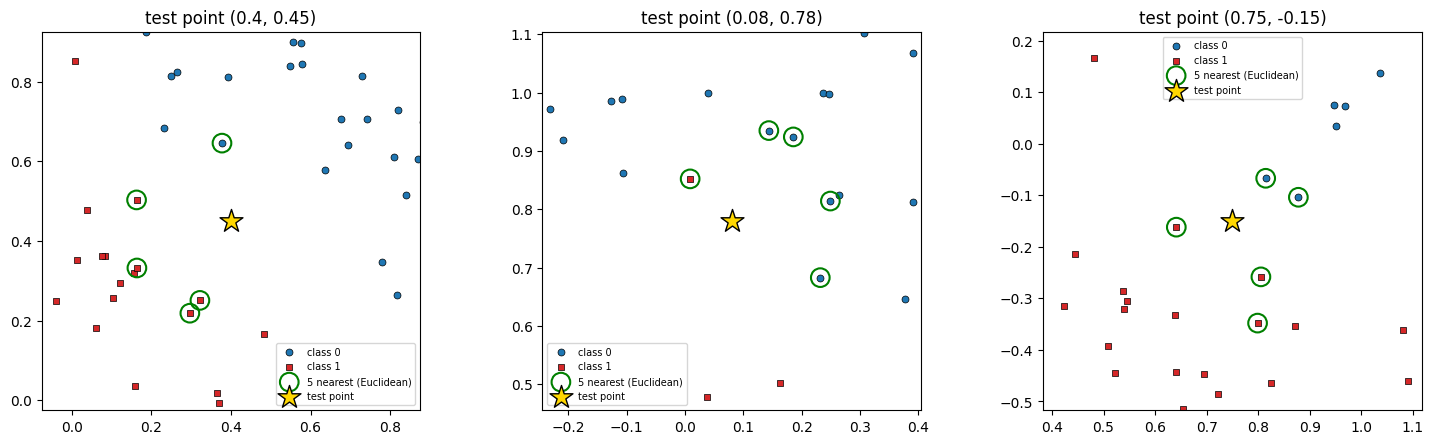

In [9]:
# where the test points sit relative to the data (zoomed in, 5 nearest Euclidean neighbors circled)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, pt in zip(axes, test_points):
    plot_points(X, y, ax)
    idx, d = k_nearest(X, np.array(pt), 5, euclidean)
    ax.scatter(X[idx, 0], X[idx, 1], s=180, facecolors="none", edgecolors="green", linewidth=1.5,
               label="5 nearest (Euclidean)")
    ax.scatter(*pt, marker="*", s=300, color="gold", edgecolor="k", zorder=5, label="test point")
    r = d[-1] * 1.8
    ax.set_xlim(pt[0] - r, pt[0] + r); ax.set_ylim(pt[1] - r, pt[1] + r)
    ax.set_aspect("equal"); ax.set_title(f"test point {pt}"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**a/b.** Votes and predicted class are in the table above.

**c. Do k and the distance measure affect the predictions?**
- **k: yes, for all three points.** The single nearest neighbor is a minority record from the other class (a noisy record near the boundary), so 1-NN disagrees with 3-NN and 5-NN:
  - (0.40, 0.45): k=1 → class 0, k=3 and k=5 → class 1 (both distances)
  - (0.08, 0.78): k=1 → class 1, k=3 and k=5 → class 0 (both distances)
  - (0.75, −0.15): Euclidean k=1 → class 0, k=3 and k=5 → class 1 (Manhattan predicts class 1 for every k)
- **Distance: yes, but only in one case.** For (0.75, −0.15) with k=1, Euclidean predicts class 0 but Manhattan predicts class 1. Its nearest Euclidean neighbor is a class-0 record offset diagonally, which Manhattan treats as farther away. In every other case both distances give the same votes.

All three points lie close to the decision boundary, which is why they are sensitive to these choices.

### Question 3d: Minimal example where Euclidean and Manhattan disagree

Two training records and one test record at the origin:

| record | position | class | Euclidean distance | Manhattan distance |
|---|---|---|---|---|
| A | (3, 0) | 0 | 3.00 | 3 |
| B | (2, 2) | 1 | 2.83 | 4 |

With 1-NN, Euclidean picks **B** (class 1) but Manhattan picks **A** (class 0). Manhattan penalizes a diagonal offset more than Euclidean does, so a point that is "close along one axis" can beat a point that is "close diagonally".

In [10]:
X_mini = np.array([[3.0, 0.0],    # A, class 0
                   [2.0, 2.0]])   # B, class 1
y_mini = np.array([0, 1])
x_q = np.array([0.0, 0.0])

for dist in [euclidean, manhattan]:
    print(f"{dist.__name__:9s}: distances A={dist(X_mini[0], x_q):.2f}, B={dist(X_mini[1], x_q):.2f}"
          f" -> 1-NN predicts class {knn_predict(X_mini, y_mini, x_q, None, 1, dist)}")

Euclidean: distances A=3.00, B=2.83 -> 1-NN predicts class 1
Manhattan: distances A=3.00, B=4.00 -> 1-NN predicts class 0


## Question 4: 1-NN vs. 10-NN decision boundary (Euclidean)

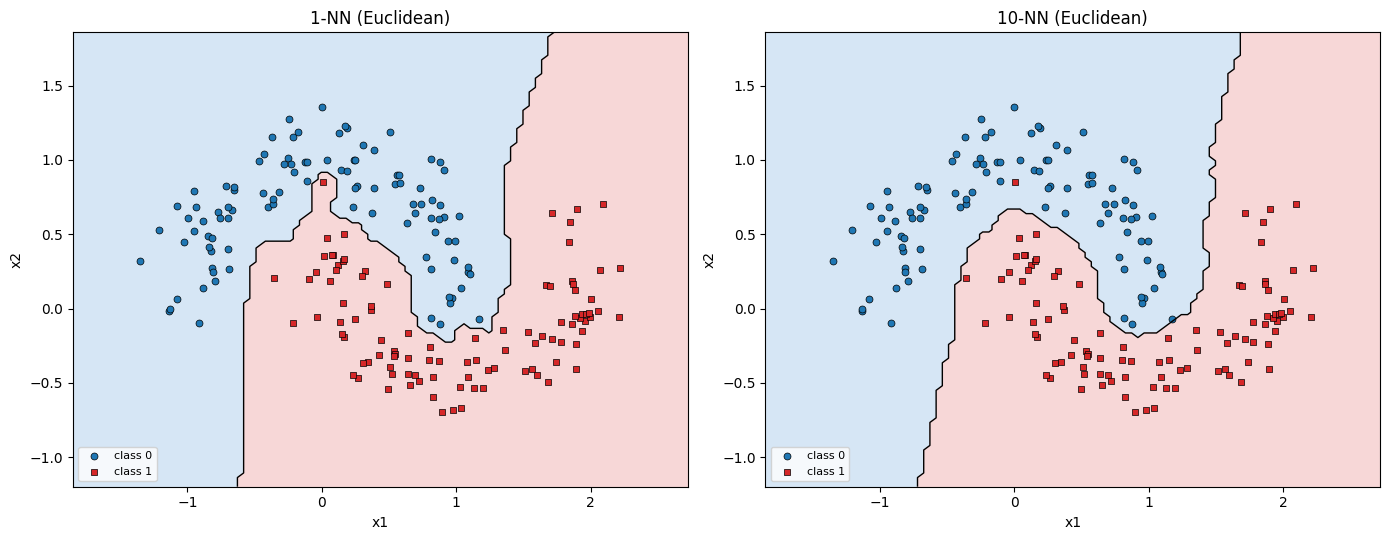

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_knn(X, y, 1, euclidean, ax=axes[0], title="1-NN (Euclidean)")
plot_knn(X, y, 10, euclidean, ax=axes[1], title="10-NN (Euclidean)")
plt.tight_layout(); plt.show()

**The 1-NN model has higher variance.** Its boundary is jagged and follows individual records: a single class-1 record inside the class-0 region (around x1 ≈ 0, x2 ≈ 0.85) creates its own spike, and the boundary zig-zags wherever the moons come close. Removing or moving one training record would change the boundary locally, so the model changes a lot between training sets. The 10-NN model averages over 10 neighbors, so single records barely matter and the boundary is smooth.

## Question 5: Training error vs. k

**a. Why does training error decrease when k decreases?**
In training-error evaluation, each training record is its own nearest neighbor (distance 0). With small k, its own vote is a large share of the k votes, and the few other neighbors are very close to it, so the prediction follows the record's own label. With large k, distant records from the other class outvote it, and the boundary gets smoother than the training data.

**b. Can training error reach zero? How to set k?**
Yes, with **k = 1**: every record is its own nearest neighbor, so it is always predicted correctly. This holds as long as no two records share the same input values with different labels (see c). On our data, 1-NN training error is 0 (table in Section 1.4).

**c. Minimal example where zero training error is impossible**
Two records with identical inputs but different classes: `((1, 1), 0)` and `((1, 1), 1)`. Any k-NN model (any k, any distance) gives the same prediction for both because their inputs are equal, so at least one of them is always wrong: training error ≥ 50%.

In [12]:
X_dup = np.array([[1.0, 1.0], [1.0, 1.0]])
y_dup = np.array([0, 1])

for k in [1, 2]:
    preds = [knn_predict(X_dup, y_dup, X_dup[i], y_dup[i], k, euclidean) for i in range(2)]
    print(f"k={k}: true labels {y_dup.tolist()}, predictions {preds}, "
          f"training error {knn_errors(X_dup, y_dup, k, euclidean)[0]:.0%}")

k=1: true labels [0, 1], predictions [0, 0], training error 50%
k=2: true labels [0, 1], predictions [0, 0], training error 50%


**d. Increasing k from 1 to n (= 200)**

Expected trend:
- **Training error** starts at 0 (k = 1) and grows with k, because the model becomes smoother and can no longer follow individual records.
- **Test error (LOOCV)** is U-shaped: high at very small k (overfitting to noise, high variance), lowest at a moderate k, and high again at large k (underfitting, high bias). At k ≈ n the model ignores the input and predicts by majority class.

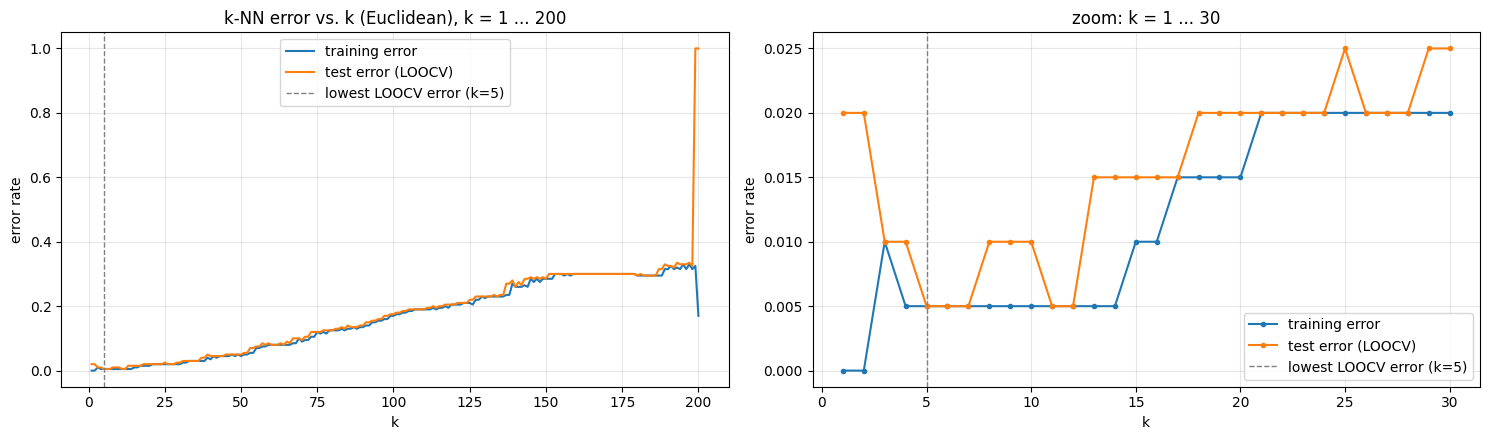

selected k values:


,k,training error,LOOCV test error
0,1,0.000,0.020
1,3,0.010,0.010
2,5,0.005,0.005
3,10,0.005,0.010
4,20,0.015,0.020
5,50,0.045,0.050
6,100,0.170,0.175
7,150,0.285,0.285
8,198,0.315,0.325
9,199,0.325,1.000


In [13]:
ks = np.arange(1, len(X) + 1)
sweep = np.array([knn_errors(X, y, k, euclidean) for k in ks])   # columns: training error, LOOCV error
best_k = ks[np.argmin(sweep[:, 1])]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, k_max in zip(axes, [len(X), 30]):          # full range, and a zoom on small k
    m = ks <= k_max
    ax.plot(ks[m], sweep[m, 0], marker="." if k_max == 30 else None, label="training error")
    ax.plot(ks[m], sweep[m, 1], marker="." if k_max == 30 else None, label="test error (LOOCV)")
    ax.axvline(best_k, color="gray", linestyle="--", linewidth=1, label=f"lowest LOOCV error (k={best_k})")
    ax.set_xlabel("k"); ax.set_ylabel("error rate"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_title("k-NN error vs. k (Euclidean), k = 1 ... 200")
axes[1].set_title("zoom: k = 1 ... 30")
plt.tight_layout(); plt.show()

print("selected k values:")
pd.DataFrame({"k": ks, "training error": sweep[:, 0], "LOOCV test error": sweep[:, 1]}) \
  .iloc[[0, 2, 4, 9, 19, 49, 99, 149, 197, 198, 199]].reset_index(drop=True)

**Observed (Euclidean):**
- **Training error** is 0 at k = 1 and rises steadily with k, to about 30% for k ≈ 150–199.
- **LOOCV test error** is 2% at k = 1, reaches its minimum of 0.5% at k = 5, and then rises together with the training error. The U-shape is shallow on the small-k side because the moons are well separated, so 1-NN only overfits a few noisy records near the boundary.
- **Edge effects at k ≈ n:**
  - k = 199 and 200: LOOCV error jumps to **100%**. When record R is left out, the remaining 199 records contain 99 of R's class and 100 of the other class. With k ≥ 199 all of them vote, so R is always outvoted.
  - k = 200: training error drops to 17%. All 200 records vote, so every prediction is a 100–100 tie. The tie-break (class with the smaller total distance) decides, which acts like "pick the class whose records are closer on average". That is a simple but reasonable classifier, which is why the error is not 50%.

So the trend matches the expectation: small k = low bias / high variance, large k = high bias, and at k = n the vote ignores where the test record is.

## Question 6: Pseudo-code for train_perceptron and train_neuron

```
function train_perceptron((x1, x2, y), lr, w1, w2, b):
    o = 1 if w1*x1 + w2*x2 + b > 0 else 0        # step activation
    error = y - o                                 # 0 if correct, +1 / -1 if wrong
    w1 = w1 + lr * error * x1
    w2 = w2 + lr * error * x2
    b  = b  + lr * error
    return w1, w2, b

function train_neuron((x, y), lr, w, b, cost_derivative, activation_derivative, activation):
    z     = w*x + b                               # forward pass
    y_hat = activation(z)
    delta = cost_derivative(y_hat, y) * activation_derivative(z)    # dC/dz (chain rule)
    dw = delta * x                                # dC/dw
    db = delta                                    # dC/db
    w = w - lr * dw                               # gradient-descent step
    b = b - lr * db
    return w, b, dw, db
```

## Question 7: Perceptron on a linearly separable dataset

**Initial boundary:** `w1 = -0.5, w2 = -0.5, b = 2` (the line $x_1 + x_2 = 4$, with the "class 1" side pointing toward the origin). It lies between the two clusters but with the classes flipped, so all 10 records are misclassified (error = 100%).

**Training:** learning rate 0.1. `train_perceptron` is called on the records one by one, in the given order, cycling through the dataset. Each call receives the `(w1, w2, b)` returned by the previous call. Training stops when the error on the whole dataset is 0 (no further call can change the weights).

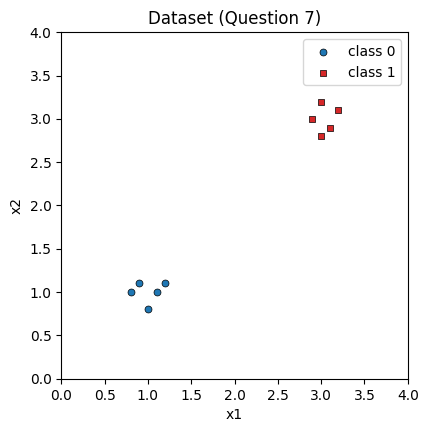

initial error: 100% | calls until error = 0: 112


In [14]:
data7 = [(0.9, 1.1, 0), (1.0, 0.8, 0), (1.1, 1.0, 0), (0.8, 1.0, 0), (1.2, 1.1, 0),
         (3.1, 2.9, 1), (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1)]


def run_perceptron(data, init, learning_rate, max_calls):
    # calls train_perceptron record by record; returns weights and dataset error after every call
    w1, w2, b = init
    history = [(w1, w2, b, perceptron_error(data, w1, w2, b), None)]   # call 0 = initial model
    for call in range(1, max_calls + 1):
        record = data[(call - 1) % len(data)]
        w1, w2, b = train_perceptron(record, learning_rate, w1, w2, b)
        history.append((w1, w2, b, perceptron_error(data, w1, w2, b), record))
        if history[-1][3] == 0:          # converged: every record correct -> no more updates
            break
    return pd.DataFrame(history, columns=["w1", "w2", "b", "error", "record used"])


def plot_perceptron(data, w1, w2, b, ax, title=""):
    pts = np.array([r[:2] for r in data]); labels = np.array([r[2] for r in data])
    g1, g2 = np.meshgrid(np.linspace(0, 4, 200), np.linspace(0, 4, 200))
    side = (w1 * g1 + w2 * g2 + b > 0).astype(int)              # predicted class on a grid
    ax.contourf(g1, g2, side, levels=[-0.5, 0.5, 1.5], colors=["#d6e6f5", "#f7d7d7"])
    if w1 != 0 or w2 != 0:
        ax.contour(g1, g2, w1 * g1 + w2 * g2 + b, levels=[0], colors="k", linewidths=1.5)
    plot_points(pts, labels, ax)
    ax.set_xlim(0, 4); ax.set_ylim(0, 4); ax.set_aspect("equal")
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title(title, fontsize=9)


# scatterplot of the dataset
fig, ax = plt.subplots(figsize=(4.5, 4.5))
pts7 = np.array([r[:2] for r in data7]); lab7 = np.array([r[2] for r in data7])
plot_points(pts7, lab7, ax)
ax.set_xlim(0, 4); ax.set_ylim(0, 4); ax.set_aspect("equal")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("Dataset (Question 7)"); ax.legend()
plt.show()

INIT = (-0.5, -0.5, 2.0)
LR_PERCEPTRON = 0.1
hist7 = run_perceptron(data7, INIT, LR_PERCEPTRON, max_calls=500)
print(f"initial error: {hist7.error[0]:.0%} | calls until error = 0: {len(hist7) - 1}")

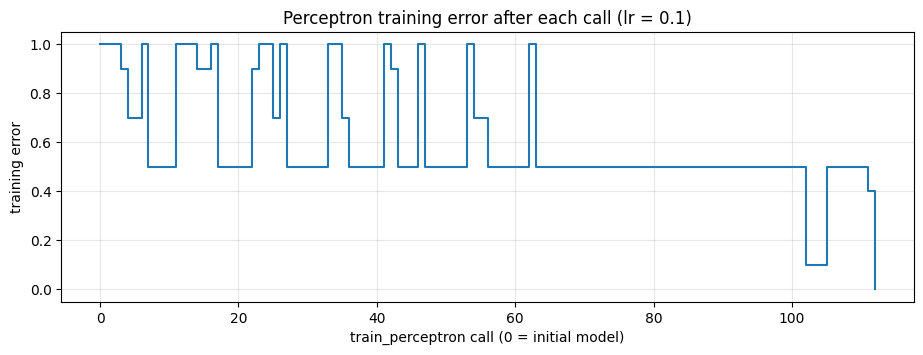

initial model: error 100%
calls   1- 10: 100%  100%   90%   70%   70%  100%   50%   50%   50%   50%
calls  11- 20: 100%  100%  100%   90%   90%  100%   50%   50%   50%   50%
calls  21- 30:  50%   90%  100%  100%   70%  100%   50%   50%   50%   50%
calls  31- 40:  50%   50%  100%  100%   70%   50%   50%   50%   50%   50%
calls  41- 50: 100%   90%   50%   50%   50%  100%   50%   50%   50%   50%
calls  51- 60:  50%   50%  100%   70%   70%   50%   50%   50%   50%   50%
calls  61- 70:  50%  100%   50%   50%   50%   50%   50%   50%   50%   50%
calls  71- 80:  50%   50%   50%   50%   50%   50%   50%   50%   50%   50%
calls  81- 90:  50%   50%   50%   50%   50%   50%   50%   50%   50%   50%
calls  91-100:  50%   50%   50%   50%   50%   50%   50%   50%   50%   50%
calls 101-110:  50%   10%   10%   10%   50%   50%   50%   50%   50%   50%
calls 111-112:  40%    0%
final weights: {'w1': 0.19, 'w2': 0.06, 'b': -0.5}


In [15]:
# training error on the entire dataset after each call
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.step(hist7.index, hist7.error, where="post")
ax.set_xlabel("train_perceptron call (0 = initial model)"); ax.set_ylabel("training error")
ax.set_title("Perceptron training error after each call (lr = 0.1)"); ax.grid(alpha=0.3)
plt.show()

# error on the entire dataset after every call, 10 calls (= one pass over the data) per line
print(f"initial model: error {hist7.error[0]:.0%}")
for start in range(1, len(hist7), 10):
    errs = hist7.error[start:start + 10]
    print(f"calls {start:3d}-{start + len(errs) - 1:3d}: " + "  ".join(f"{e:4.0%}" for e in errs))
print("final weights:", hist7.iloc[-1][["w1", "w2", "b"]].astype(float).round(3).to_dict())

**Decision boundary after consecutive calls.** The first 10 calls (one pass over the data), then the last calls before convergence. Shaded region = predicted class, black line = decision boundary.

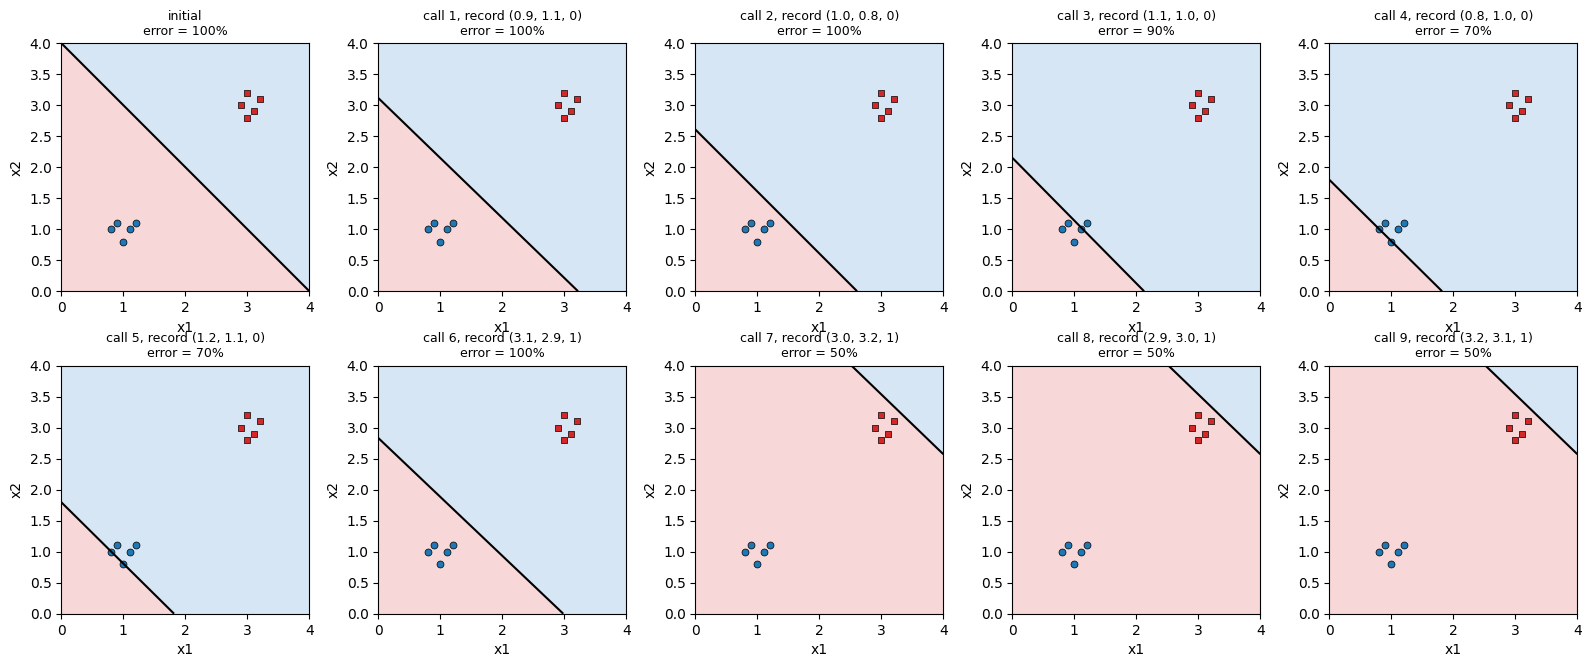

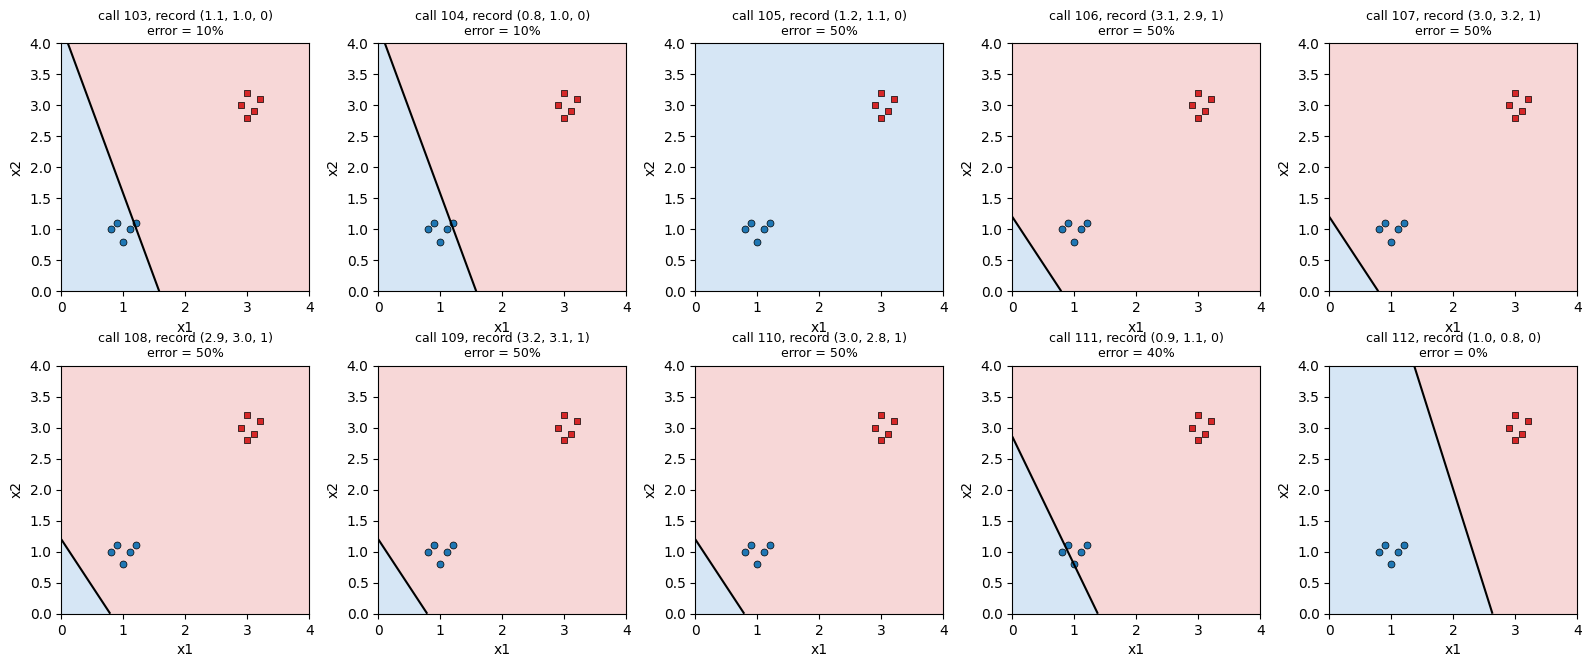

In [16]:
def plot_calls(hist, data, calls, ncols=5):
    nrows = int(np.ceil(len(calls) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.3 * nrows))
    for ax, c in zip(axes.ravel(), calls):
        w1, w2, b, err, rec = hist.loc[c, ["w1", "w2", "b", "error", "record used"]]
        label = "initial" if c == 0 else f"call {c}, record {rec}"
        plot_perceptron(data, w1, w2, b, ax, f"{label}\nerror = {err:.0%}")
    for ax in axes.ravel()[len(calls):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()


last = len(hist7) - 1
plot_calls(hist7, data7, list(range(0, 10)))                      # initial model + first 9 calls
plot_calls(hist7, data7, list(range(last - 9, last + 1)))         # last 10 calls

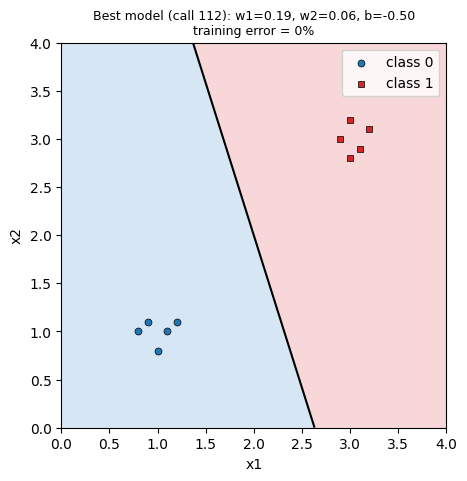

In [17]:
# model with minimal training error (first call that reached it)
best = hist7.error.idxmin()
w1, w2, b = hist7.loc[best, ["w1", "w2", "b"]]
fig, ax = plt.subplots(figsize=(5, 5))
plot_perceptron(data7, w1, w2, b, ax,
                f"Best model (call {best}): w1={w1:.2f}, w2={w2:.2f}, b={b:.2f}\n"
                f"training error = {hist7.error[best]:.0%}")
ax.legend(); plt.show()

**How the perceptron learns** (lr = 0.1, starting from 100% error):
- Calls on class-0 records first move the boundary toward the origin (error 100% → 70%), then the class-1 records flip it to the other orientation (call 7: error 50%).
- After that, the error mostly sits at 50% (all records on one side) while every mistake nudges w1, w2 and b by 0.1·x. Each pass rotates and shifts the line a bit more.
- At call 112 (≈ 11 passes) the error reaches **0%**, with **w1 = 0.19, w2 = 0.06, b = −0.5**.

**Does the best model perfectly separate the classes? Yes.** Training error is 0: every class-0 record is on one side of the line and every class-1 record on the other. This is guaranteed by the perceptron convergence theorem, since the data is linearly separable. After that, every call sees a correctly classified record, so the weights stop changing.

## Question 8: Adding the record (1.0, 1.0, 1)

Same initial weights and learning rate, now with the extra record. We allow up to 100 passes over the data (1100 calls).

calls run: 1100 | minimum error reached: 9.1% | error after last call: 27.3%


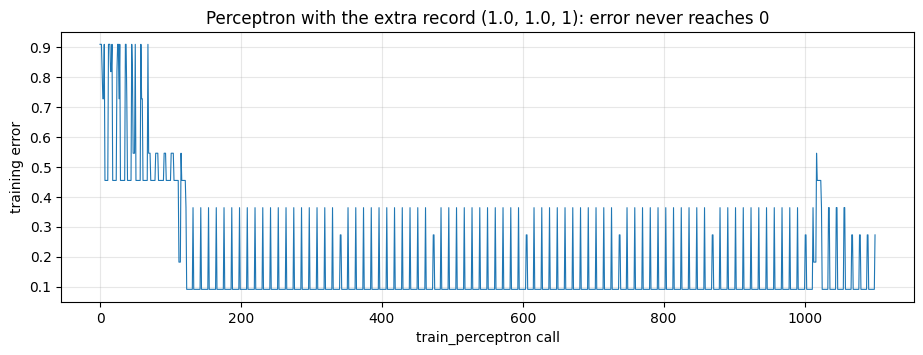

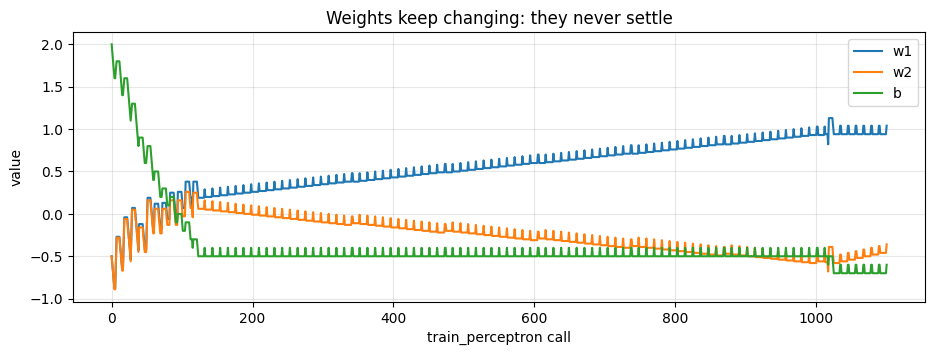

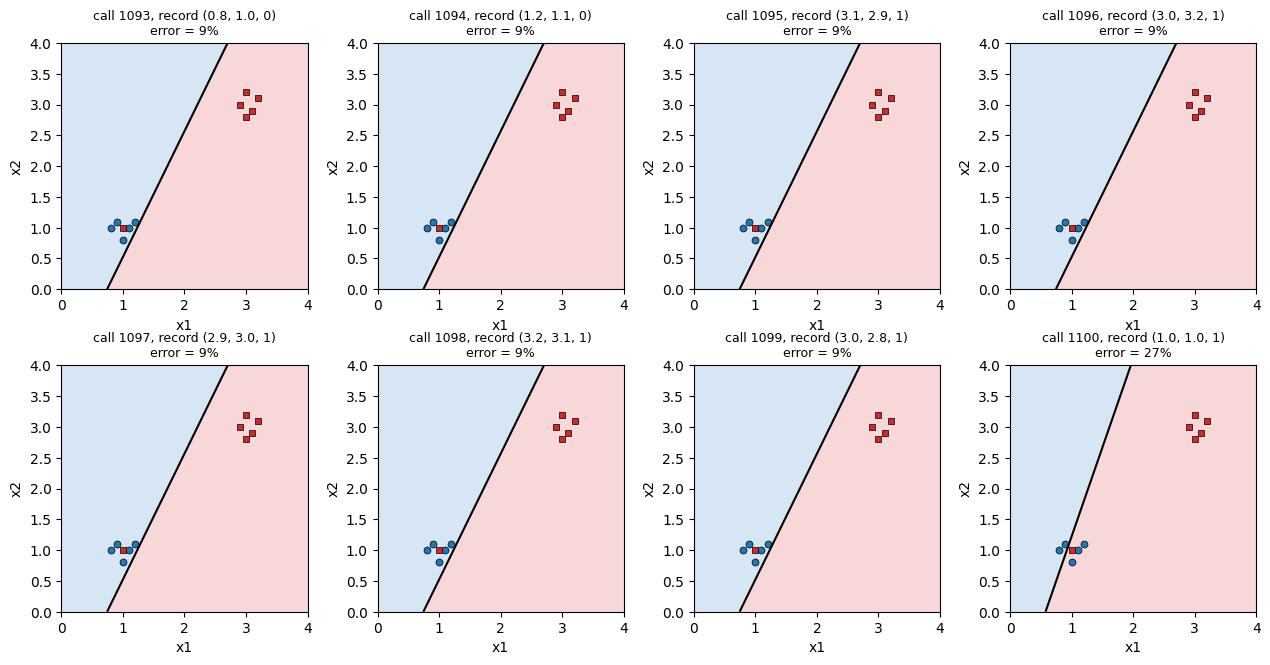

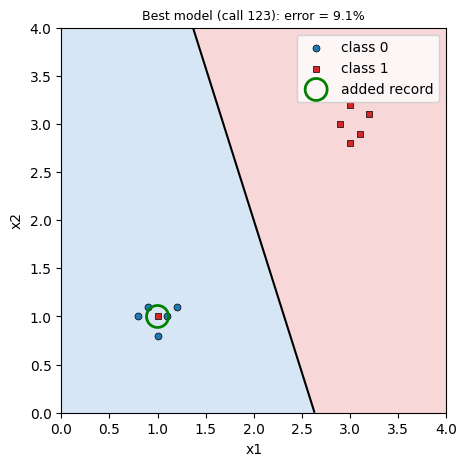

In [18]:
data8 = data7 + [(1.0, 1.0, 1)]
hist8 = run_perceptron(data8, INIT, LR_PERCEPTRON, max_calls=100 * len(data8))
print(f"calls run: {len(hist8) - 1} | minimum error reached: {hist8.error.min():.1%} "
      f"| error after last call: {hist8.error.iloc[-1]:.1%}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(hist8.index, hist8.error, linewidth=0.8)
ax.set_xlabel("train_perceptron call"); ax.set_ylabel("training error")
ax.set_title("Perceptron with the extra record (1.0, 1.0, 1): error never reaches 0"); ax.grid(alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5))
for col in ["w1", "w2", "b"]:
    ax.plot(hist8.index, hist8[col], label=col)
ax.set_xlabel("train_perceptron call"); ax.set_ylabel("value"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Weights keep changing: they never settle")
plt.show()

plot_calls(hist8, data8, list(range(len(hist8) - 8, len(hist8))), ncols=4)   # last 8 calls

# best model found (lowest training error)
best8 = hist8.error.idxmin()
w1, w2, b = hist8.loc[best8, ["w1", "w2", "b"]]
fig, ax = plt.subplots(figsize=(5, 5))
plot_perceptron(data8, w1, w2, b, ax, f"Best model (call {best8}): error = {hist8.error[best8]:.1%}")
ax.scatter(1.0, 1.0, s=250, facecolors="none", edgecolors="green", linewidth=2, label="added record")
ax.legend(); plt.show()

**What happens:** the perceptron **never converges**. Over 1100 calls the error keeps jumping (mostly between 9% and 36%) and the weights never settle. The best model reached 9.1% = 1/11, which misclassifies only the new record.

**Why:** the new record (1.0, 1.0) has class 1 but lies **inside** the class-0 cluster (inside the convex hull of the class-0 points). No straight line can put it on the class-1 side without also putting class-0 records there, so the data is **not linearly separable**. The perceptron rule updates the weights after every mistake, and there is always at least one mistake. Updating on (1.0, 1.0) pulls the boundary into the class-0 cluster, then the class-0 records push it back out, so the weights cycle forever.

## Question 9: Training a single neuron for y = 2x + 3

**Data:** the HW2 generator, copied below: 100 records, x uniform in [0, 1], y = 2x + 3 + noise with noise uniform in [−0.1, 0.1].

**Target scaling:** sigmoid outputs lie in (0, 1) and tanh outputs in (−1, 1), so neither can output y ∈ [3, 5]. Cross-entropy also requires targets in [0, 1]. So for training, y is min-max scaled into **[0.1, 0.9]**. All plots and errors are converted back to the original y units, so the models can be compared directly.

**Training setup (same for every run):** start at `w = 0.1, b = 0.1`, records visited in the same order each epoch, one `train_neuron` call per record (1 epoch = 100 calls). Starting from `w = b = 0` would make ReLU stuck forever, since its derivative at z = 0 is 0.

**Model quality** is measured as RMSE between the model and the **true** function on a dense grid of x-values (in original y units).

In [19]:
# ---------- HW2 data generator ----------
def make_features(x, funcs):
    # input attributes: x itself, followed by one column per extra function f_i(x)
    return np.column_stack([x] + [f(x) for f in funcs])


def generate_noisy_dataset(funcs, true_f, x_range, n, eps, seed=0):
    # y = true_f(x) + noise, noise ~ Uniform[-eps, eps]
    rng = np.random.default_rng(seed)
    x = rng.uniform(x_range[0], x_range[1], n)
    X = make_features(x, funcs)
    y = true_f(x) + rng.uniform(-eps, eps, n)
    return X, y


true_f = lambda x: 2 * x + 3
X9, y9 = generate_noisy_dataset([], true_f, (0, 1), 100, 0.1)
x9 = X9[:, 0]

# ---------- scale y into [0.1, 0.9] for training, and back for plotting ----------
Y_MIN, Y_MAX = y9.min(), y9.max()
to_unit = lambda v: 0.1 + 0.8 * (v - Y_MIN) / (Y_MAX - Y_MIN)
from_unit = lambda u: Y_MIN + (u - 0.1) * (Y_MAX - Y_MIN) / 0.8
y9_s = to_unit(y9)

X_GRID = np.linspace(0, 1, 200)
print("x range:", x9.min().round(3), "-", x9.max().round(3), "| y range:", Y_MIN.round(3), "-", Y_MAX.round(3))

x range: 0.003 - 0.997 | y range: 2.911 - 5.082


In [20]:
def fit_neuron(x, y_s, act_name, cost_name, learning_rate, epochs, w0=0.1, b0=0.1):
    # trains with train_neuron, one record at a time; records state after every epoch
    act, act_d = ACTIVATIONS[act_name]
    cost, cost_d = COSTS[cost_name]
    w, b = w0, b0
    hist = {"w": [w], "b": [b], "dw": [], "db": [], "rmse": [], "cost": []}

    def record_epoch(w, b):
        y_hat_grid = from_unit(np.array([act(w * xg + b) for xg in X_GRID]))
        hist["rmse"].append(np.sqrt(np.mean((y_hat_grid - true_f(X_GRID)) ** 2)))
        hist["cost"].append(np.mean([cost(act(w * xi + b), yi) for xi, yi in zip(x, y_s)]))

    record_epoch(w, b)
    with np.errstate(over="ignore", invalid="ignore"):
        for _ in range(epochs):
            for xi, yi in zip(x, y_s):
                w, b, dw, db = train_neuron((xi, yi), learning_rate, w, b, cost_d, act_d, act)
                hist["dw"].append(dw); hist["db"].append(db)     # gradient of every call
            hist["w"].append(w); hist["b"].append(b)
            record_epoch(w, b)
    return {k: np.array(v) for k, v in hist.items()}


def model_curve(act_name, w, b):
    act = ACTIVATIONS[act_name][0]
    return from_unit(np.array([act(w * xg + b) for xg in X_GRID]))

### 9a. How the model changes during training

All 6 combinations of activation (sigmoid, tanh, ReLU) and cost (squared error, cross-entropy), learning rate 0.1, 300 epochs.

In [21]:
LR, EPOCHS = 0.1, 300
combos = [(a, c) for a in ["sigmoid", "tanh", "relu"] for c in ["squared error", "cross-entropy"]]
runs = {combo: fit_neuron(x9, y9_s, *combo, learning_rate=LR, epochs=EPOCHS) for combo in combos}


def animate_fit(hist, act_name, cost_name, n_frames=40):
    # movie: data + true function + model after each shown epoch
    fig, ax = plt.subplots(figsize=(6.5, 4), dpi=80)
    ax.scatter(x9, y9, s=10, color="gray", alpha=0.5, label="data")
    ax.plot(X_GRID, true_f(X_GRID), "--", color="tab:orange", linewidth=2, label="true y = 2x + 3")
    line, = ax.plot([], [], color="tab:blue", linewidth=2, label="model")
    ax.set_xlim(0, 1); ax.set_ylim(2.5, 5.5); ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend(loc="upper left")
    # more frames early (where the model changes fast), fewer later
    frames = np.unique(np.geomspace(1, len(hist["w"]), n_frames).astype(int) - 1)

    def update(e):
        line.set_data(X_GRID, model_curve(act_name, hist["w"][e], hist["b"][e]))
        ax.set_title(f"{act_name} + {cost_name} | epoch {e} | RMSE vs. true f = {hist['rmse'][e]:.3f}")
        return line,

    ani = FuncAnimation(fig, update, frames=frames, interval=200, blit=True)
    plt.close(fig)
    return HTML(ani.to_jshtml())


display(animate_fit(runs[("sigmoid", "cross-entropy")], "sigmoid", "cross-entropy"))

In [22]:
display(animate_fit(runs[("relu", "squared error")], "relu", "squared error"))

Snapshots of every combination (model after epochs 0, 1, 5, 20, 100, 300):

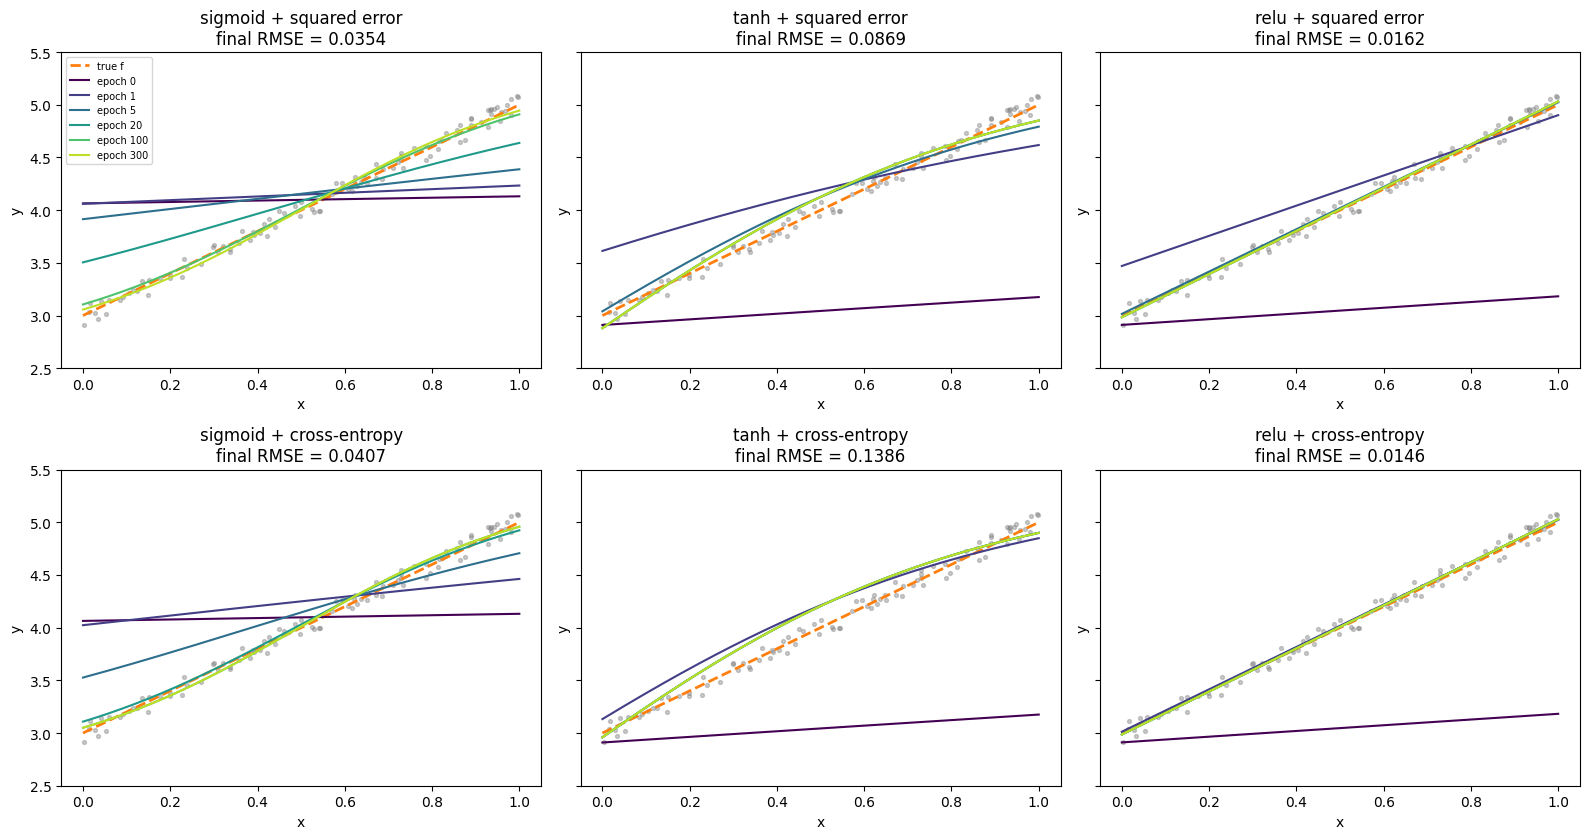

In [23]:
snap_epochs = [0, 1, 5, 20, 100, 300]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(snap_epochs)))
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharey=True)
for j, act_name in enumerate(["sigmoid", "tanh", "relu"]):
    for i, cost_name in enumerate(["squared error", "cross-entropy"]):
        ax, h = axes[i, j], runs[(act_name, cost_name)]
        ax.scatter(x9, y9, s=8, color="gray", alpha=0.4)
        ax.plot(X_GRID, true_f(X_GRID), "--", color="tab:orange", linewidth=2, label="true f")
        for e, col in zip(snap_epochs, colors):
            ax.plot(X_GRID, model_curve(act_name, h["w"][e], h["b"][e]), color=col, label=f"epoch {e}")
        ax.set_ylim(2.5, 5.5); ax.set_title(f"{act_name} + {cost_name}\nfinal RMSE = {h['rmse'][-1]:.4f}")
        ax.set_xlabel("x"); ax.set_ylabel("y")
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 9b. Which activation and cost work best?

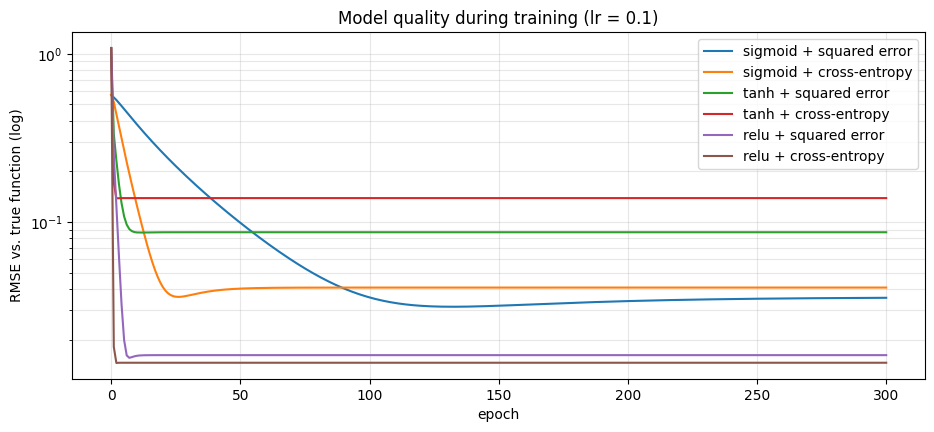

,activation,cost,final w,final b,RMSE after 20 epochs,final RMSE
0,relu,cross-entropy,0.7530,0.1275,0.0146,0.0146
1,relu,squared error,0.7549,0.1268,0.0162,0.0162
2,sigmoid,squared error,3.4377,-1.7060,0.2567,0.0354
3,sigmoid,cross-entropy,3.4943,-1.7244,0.0410,0.0407
4,tanh,squared error,1.0526,0.0887,0.0868,0.0869
5,tanh,cross-entropy,1.0792,0.1184,0.1386,0.1386


In [24]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for combo, h in runs.items():
    ax.plot(h["rmse"], label=f"{combo[0]} + {combo[1]}")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("RMSE vs. true function (log)")
ax.set_title("Model quality during training (lr = 0.1)"); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.show()

summary = pd.DataFrame([{"activation": a, "cost": c, "final w": h["w"][-1], "final b": h["b"][-1],
                         "RMSE after 20 epochs": h["rmse"][20], "final RMSE": h["rmse"][-1]}
                        for (a, c), h in runs.items()])
summary.sort_values("final RMSE").reset_index(drop=True).round(4)

**ReLU works best (with either cost), then sigmoid, then tanh.**

How we can tell: the final RMSE vs. the true function, plus the plots (the ReLU line lies on the dashed true line).
- **ReLU** (RMSE ≈ 0.015–0.016): it is linear for z > 0, and the neuron stays in that region, so it can represent y = 2x + 3 exactly. Its result matches the least-squares line (Question 9e), which is the best any line can do on this noisy data.
- **Sigmoid** (≈ 0.035–0.041): the middle of the S-curve is almost linear, so the fit is good, but a small curvature remains.
- **Tanh** (≈ 0.09–0.14): for z > 0 tanh is concave, so the fitted curve bends visibly.

**Cost function:** cross-entropy makes sigmoid learn much faster (RMSE after 20 epochs: 0.041 vs. 0.257 with squared error). With sigmoid + cross-entropy the σ′(z) factor cancels out: δ = ŷ − y. With squared error, δ = (ŷ − y)·σ′(z), and σ′(z) ≤ 0.25 shrinks every step. The final quality is similar for both costs.

Note: cross-entropy assumes predictions in (0, 1). ReLU + cross-entropy only works here because the scaled targets lie in [0.1, 0.9] and the predictions stayed in (0, 1). For regression, ReLU + squared error is the natural choice.

### 9c. Effect of the learning rate

Learning rates 0.001, 0.01, 0.1, 1, 10 for two combinations: **sigmoid + cross-entropy** and **ReLU + squared error**.

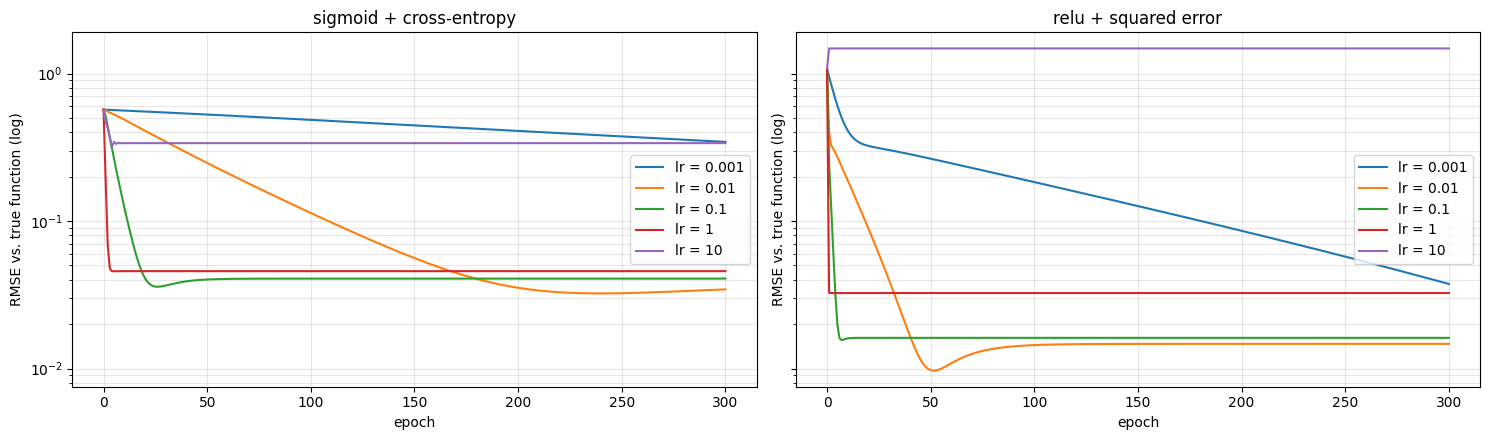

,combination,lr,final w,final b,final RMSE
0,sigmoid + cross-entropy,0.001,1.3286,-0.4920,0.3439
1,sigmoid + cross-entropy,0.010,3.4129,-1.6868,0.0344
2,sigmoid + cross-entropy,0.100,3.4943,-1.7244,0.0407
3,sigmoid + cross-entropy,1.000,3.5171,-1.7181,0.0458
4,sigmoid + cross-entropy,10.000,4.6962,-2.9724,0.3374
5,relu + squared error,0.001,0.6958,0.1603,0.0375
6,relu + squared error,0.010,0.7547,0.1258,0.0147
7,relu + squared error,0.100,0.7549,0.1268,0.0162
8,relu + squared error,1.000,0.7497,0.1378,0.0325
9,relu + squared error,10.000,-10.4350,-44.8977,1.4788


In [25]:
lrs = [0.001, 0.01, 0.1, 1, 10]
lr_runs = {(combo, lr): fit_neuron(x9, y9_s, *combo, learning_rate=lr, epochs=EPOCHS)
           for combo in [("sigmoid", "cross-entropy"), ("relu", "squared error")] for lr in lrs}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, combo in zip(axes, [("sigmoid", "cross-entropy"), ("relu", "squared error")]):
    for lr in lrs:
        ax.plot(lr_runs[(combo, lr)]["rmse"], label=f"lr = {lr}")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("RMSE vs. true function (log)")
    ax.set_title(f"{combo[0]} + {combo[1]}"); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

pd.DataFrame([{"combination": f"{c[0]} + {c[1]}", "lr": lr, "final w": h["w"][-1], "final b": h["b"][-1],
               "final RMSE": h["rmse"][-1]} for (c, lr), h in lr_runs.items()]).round(4)

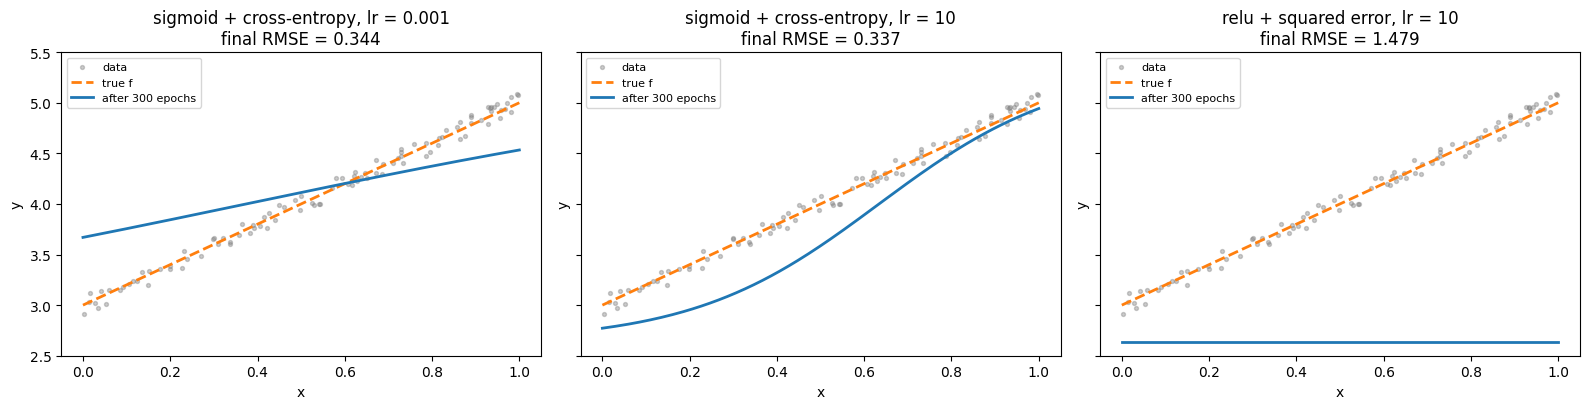

In [26]:
# extreme examples: model after the last epoch
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (combo, lr) in zip(axes, [(("sigmoid", "cross-entropy"), 0.001),
                                  (("sigmoid", "cross-entropy"), 10),
                                  (("relu", "squared error"), 10)]):
    h = lr_runs[(combo, lr)]
    ax.scatter(x9, y9, s=8, color="gray", alpha=0.4, label="data")
    ax.plot(X_GRID, true_f(X_GRID), "--", color="tab:orange", linewidth=2, label="true f")
    ax.plot(X_GRID, model_curve(combo[0], h["w"][-1], h["b"][-1]), color="tab:blue", linewidth=2,
            label=f"after {EPOCHS} epochs")
    ax.set_ylim(2.5, 5.5); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=8)
    ax.set_title(f"{combo[0]} + {combo[1]}, lr = {lr}\nfinal RMSE = {h['rmse'][-1]:.3f}")
plt.tight_layout(); plt.show()

- **Too small (0.001):** very slow. After 300 epochs, sigmoid + cross-entropy is still far from the true line (RMSE 0.34), and ReLU is still improving (0.038).
- **Medium (0.01–0.1):** smooth convergence to a good model. lr = 0.1 converges in about 10–25 epochs.
- **Large (1):** converges within a few epochs, but to a slightly worse model (RMSE 0.046 / 0.033). Each single-record step is large, so the parameters keep jumping around the minimum instead of settling in it.
- **Too large (10): training fails.**
  - Sigmoid + cross-entropy overshoots and ends in a poor fit (RMSE 0.34).
  - ReLU + squared error: one huge step makes z = wx + b negative for every x (w = −10.4, b = −44.9). ReLU then outputs 0 with derivative 0, so all later gradients are 0 and the neuron is "dead" forever (RMSE 1.48).

The learning rate trades off speed against stability: too small wastes epochs, too large overshoots or breaks the model.

### 9d. Gradients during training

`train_neuron` returns `dw` and `db` for every call. Below: the gradient of every call (gray dots) and the average per epoch (red line) over the first 50 epochs, for sigmoid + cross-entropy and ReLU + squared error at lr = 0.1. The per-epoch average equals the full-dataset gradient, up to the small weight changes within an epoch.

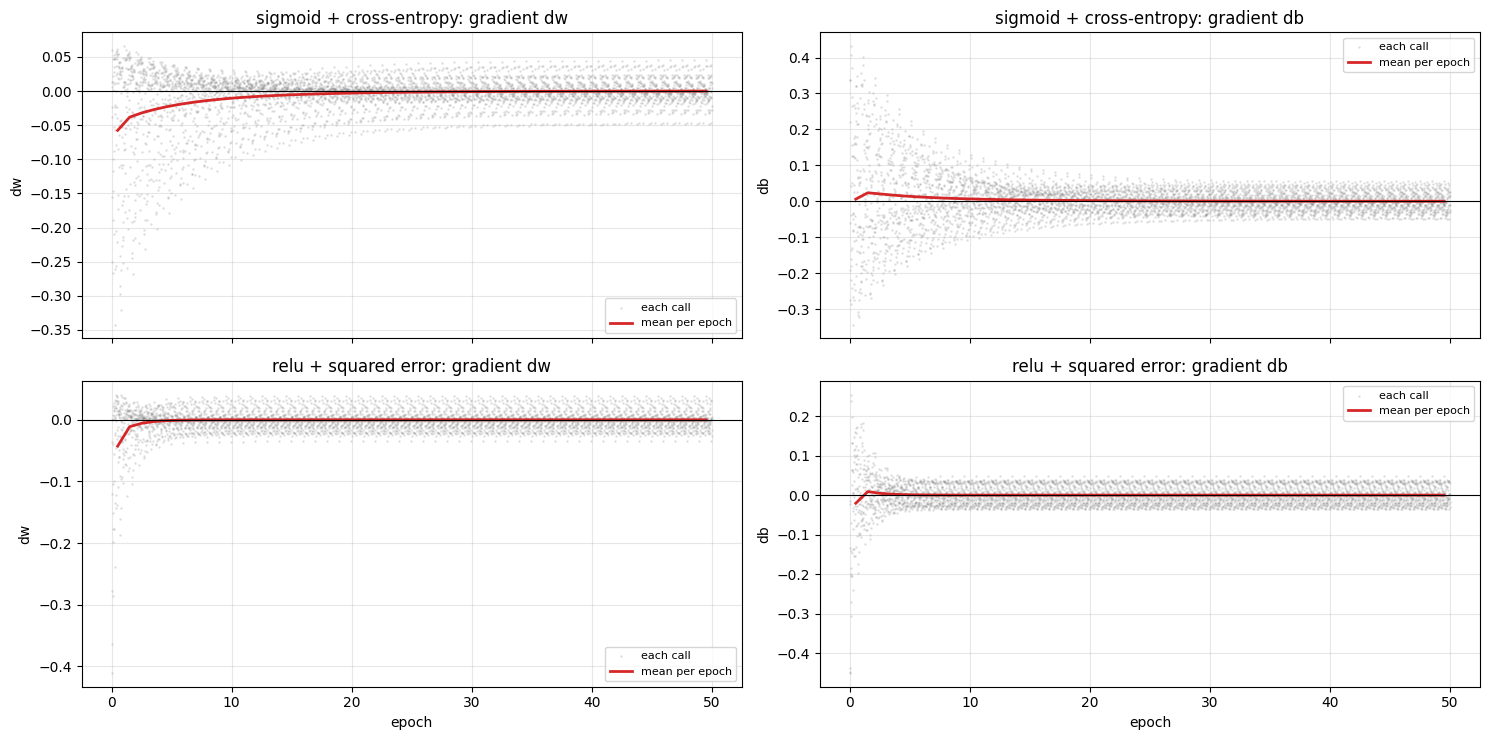

In [27]:
SHOW_EPOCHS = 50
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharex=True)
for row, combo in enumerate([("sigmoid", "cross-entropy"), ("relu", "squared error")]):
    h = runs[combo]
    calls_per_epoch = len(x9)
    for col, g in enumerate(["dw", "db"]):
        ax = axes[row, col]
        per_call = h[g][:SHOW_EPOCHS * calls_per_epoch]
        epoch_axis = np.arange(len(per_call)) / calls_per_epoch          # call index in epochs
        epoch_mean = per_call.reshape(-1, calls_per_epoch).mean(axis=1)
        ax.scatter(epoch_axis, per_call, s=1, alpha=0.15, color="tab:gray", label="each call")
        ax.plot(np.arange(len(epoch_mean)) + 0.5, epoch_mean, color="tab:red", linewidth=2,
                label="mean per epoch")
        ax.axhline(0, color="k", linewidth=0.8)
        ax.set_title(f"{combo[0]} + {combo[1]}: gradient {g}"); ax.set_ylabel(g)
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()

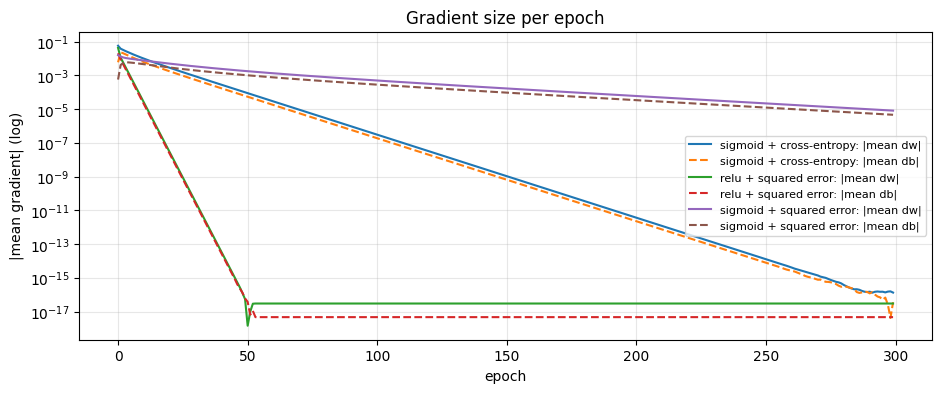

In [28]:
# size of the per-epoch mean gradient, log scale
fig, ax = plt.subplots(figsize=(11, 4))
for combo in [("sigmoid", "cross-entropy"), ("relu", "squared error"), ("sigmoid", "squared error")]:
    h = runs[combo]
    for g, ls in [("dw", "-"), ("db", "--")]:
        mean_g = h[g].reshape(-1, len(x9)).mean(axis=1)
        ax.plot(np.abs(mean_g), ls, label=f"{combo[0]} + {combo[1]}: |mean {g}|")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("|mean gradient| (log)")
ax.set_title("Gradient size per epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.show()

**How the gradient changes:**
- **Mean gradient per epoch:** large at the start, then it **shrinks toward 0 roughly exponentially**, a straight line on the log plot. ReLU + squared error reaches numerical precision (~10⁻¹⁶) around epoch 50, sigmoid + cross-entropy takes longer, and sigmoid + squared error is slowest.
- **Single-call gradients** do **not** go to 0. They settle into a band of about ±0.05 around 0.

**Why:**
- Every gradient contains the error term (ŷ − y). As the model approaches the minimum, the systematic error shrinks, so the gradient shrinks too. Near the minimum each epoch removes a roughly constant fraction of the remaining error, which gives the exponential decay.
- Sigmoid + squared error is slowest because each gradient is also multiplied by σ′(z) ≤ 0.25.
- The single-call gradients stay non-zero because every record has its own noise (±0.1), so even the best line has a non-zero error ŷ − y on each record. These per-record gradients point in different directions and cancel out on average, which is why the per-epoch mean goes to 0 while individual calls do not.

### 9e. Linear activation

With $a(z) = z$ the neuron is $\hat{y} = wx + b$: plain **linear regression**, trained by gradient descent instead of the normal equation from HW2. Below it is trained with squared error (cross-entropy is not meaningful since $\hat{y}$ is unbounded) and compared with the least-squares solution.

In [29]:
h_lin = fit_neuron(x9, y9_s, "linear", "squared error", learning_rate=0.1, epochs=EPOCHS)

# least-squares solution on the same (scaled) data, via the HW2 normal equation
Xb = np.column_stack([np.ones_like(x9), x9])
b_ls, w_ls = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y9_s

print(f"gradient descent: w = {h_lin['w'][-1]:.4f}, b = {h_lin['b'][-1]:.4f}, final RMSE = {h_lin['rmse'][-1]:.4f}")
print(f"normal equation : w = {w_ls:.4f}, b = {b_ls:.4f}")

# same model in original units: y = from_unit(w*x + b)
slope = h_lin["w"][-1] * (Y_MAX - Y_MIN) / 0.8
intercept = from_unit(h_lin["b"][-1])
print(f"in original units: y = {slope:.3f} x + {intercept:.3f}   (true: y = 2x + 3)")

h_lin_big = fit_neuron(x9, y9_s, "linear", "squared error", learning_rate=10, epochs=5)
print("linear activation, lr = 10 -> w after each epoch:", ", ".join(f"{v:.2e}" for v in h_lin_big["w"]))

gradient descent: w = 0.7549, b = 0.1268, final RMSE = 0.0162
normal equation : w = 0.7549, b = 0.1253
in original units: y = 2.048 x + 2.984   (true: y = 2x + 3)
linear activation, lr = 10 -> w after each epoch: 1.00e-01, -1.51e+106, -9.40e+212, nan, nan, nan


- **The neuron becomes ordinary linear regression.** Gradient descent finds the same model as the HW2 normal equation (w = 0.7549 in both; b differs only in the third decimal because of the single-record updates). In original units this is y ≈ 2.05x + 2.98, close to y = 2x + 3.
- **For this linear target it works well:** the derivative is always 1, so there is no saturation and no vanishing gradient, and targets would not even need scaling.
- **Downsides:**
  - No non-linearity: it can only model straight lines. Even a multi-layer network with only linear activations collapses to one linear function, since W₂(W₁x + b₁) + b₂ is still linear.
  - Unbounded output: nothing limits the step size, so a large learning rate diverges quickly. With lr = 10, w explodes to 10²¹² and then becomes NaN.
  - Cross-entropy can't be used, because ŷ is not a probability.

## Question 10: Multi-layer perceptron from the demo notebook

The demo (`HW3-gradient_flow_mnist.ipynb`) was run with its default parameters: `HIDDEN_UNITS = [32, 32, 32, 32]`, `ACTIVATIONS = ['sigmoid'] * 5`, `COST_FUNCTION = 'mse'`, SGD, lr = 0.05, batch size 128, 60 epochs.

**Architecture:** 784 inputs → 32 → 32 → 32 → 32 → 10 outputs.
- **5 layers with weights:** 4 hidden layers (32 units each) + 1 output layer (10 units, one per digit). Counting the input layer, the network has 6 layers.
- **Activation: sigmoid in every layer**, including the output layer.
- Parameters: 784·32 + 32 = 25,120 for hidden layer 1, 32·32 + 32 = 1,056 for each of hidden layers 2–4, 32·10 + 10 = 330 for the output layer, **28,618 in total**.

## Question 11: Explaining the gradient plot

**What the plot shows:** one curve per layer. Each point is the size of that layer's gradient (L1 norm of all weight and bias gradients, divided by the number of parameters, so the average |gradient| per parameter), measured on 10,000 training images after each epoch. Epoch 0 is before training. The y-axis is logarithmic.

**Shape of the curves:** every curve drops steeply during the first ~10 epochs (by 2–3 orders of magnitude) and is then completely flat until epoch 60. The network quickly reaches a point where the gradient is tiny everywhere, and it stays there.

**Difference between the curves:** the curves are strictly ordered by depth. The output layer has the largest gradient and hidden layer 1 the smallest, about 3,800× smaller at epoch 0 (2.5e-6 vs. 9.6e-3) and about 300× smaller at the end (7.7e-8 vs. 2.3e-5). This is the **vanishing gradient** problem. Backpropagation multiplies the gradient by σ′(z) ≤ 0.25 (and by the weights) once per sigmoid layer, so very little signal reaches the first layers, and they barely change.

**Is the network learning? No.** After 60 epochs the test accuracy is 11.35%, which is chance level: it equals always predicting digit "1", the most frequent class in the test set. The train and test cost are both 0.0900, exactly the MSE of outputting 0.1 for every class regardless of the image. The network only learned this constant output (mostly by adjusting the output layer's biases). After that, the remaining gradients are too small for SGD to make progress, so the flat curves mean "stuck", not "converged to a good model".

## Question 12: Other activation and cost functions

Three configurations of the demo (only `ACTIVATIONS` and `COST_FUNCTION` changed; SGD, lr = 0.05, 60 epochs). Cross-entropy in the demo applies softmax itself, so the output activation must be `'identity'`.

| run | `ACTIVATIONS` | `COST_FUNCTION` | train cost | test cost | test accuracy |
|---|---|---|---|---|---|
| A (default) | `['sigmoid'] * 5` | `'mse'` | 0.0900 | 0.0900 | 11.35% |
| B | `['sigmoid'] * 4 + ['identity']` | `'cross_entropy'` | 0.2804 | 0.3879 | 91.11% |
| C | `['relu'] * 4 + ['identity']` | `'cross_entropy'` | 0.0088 | 0.2186 | 96.70% |

(Costs of A are MSE and of B/C cross-entropy, so they can only be compared within the same cost.)

**How the gradients change with cross-entropy**

- **Run B (sigmoid + cross-entropy):** at the output, the gradient is now softmax(output) − one-hot label. It is no longer damped by σ′(z) of a saturated sigmoid output unit, so the output-layer gradient stays around 10⁻³ instead of collapsing to 10⁻⁵ as in run A.
  - For the first ~15 epochs the hidden layers still show the vanishing-gradient pattern: hidden layer 1 is about 300× below the output layer.
  - Their gradients then grow steadily (hidden 1: ~5·10⁻⁶ → ~10⁻³ by epoch 30) as the hidden units leave their flat starting region and start learning useful features.
  - From about epoch 30 on, all layers have similar gradient sizes (10⁻³–10⁻²), and accuracy reaches 91%.
- **Run C (ReLU + cross-entropy):** the gradients jump to about 10⁻² within the first 2 epochs, and **all layers stay within a factor of ~2–5 of each other** for the whole run. ReLU's derivative is 1 for active units, so the gradient is not shrunk layer by layer and there is **no vanishing gradient**. The curves are spiky because of mini-batch SGD with a fixed learning rate, and they drift slightly downward as the model fits the training data better.

Compared with run A, the gradients in B and C are 100–10,000× larger, which is what makes learning possible.

**When does the network learn best?** With **ReLU hidden layers + cross-entropy** (run C):
- it learns from the first epoch,
- it reaches the lowest test cost (0.2186), and
- it reaches the highest test accuracy (96.70%).

Sigmoid + cross-entropy (run B) also learns, but only after a slow start, and it ends lower (91.11%). Sigmoid + MSE (run A) doesn't learn at all.

The lesson is the same as in Question 9b: avoid stacking saturating activations, and pair the output with a cost whose gradient doesn't vanish.

One caveat for run C: train cost (0.0088) is much lower than test cost (0.2186), so after 60 epochs the network is starting to **overfit** the training data.